<a href="https://colab.research.google.com/github/cs-iuu/ai-2026-fall-nlp/blob/main/notebook/12_word2vec.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Static Word Embeddings: From One-Hot to Word2Vec
### Introduction to AI — NLP Lab

This lab explains why static word embeddings were an important improvement over one-hot vectors and why contextual embeddings were needed later.

You will:

1. Compare one-hot and dense vectors.
2. Generate CBOW and Skip-gram training examples.
3. Train both Word2Vec architectures on the same corpus.
4. Explore cosine similarity and nearest neighbors.
5. Visualize selected static embeddings.
6. Demonstrate the polysemy limitation: one word type still has one vector.

The built-in corpus is intentionally small so every cell runs. Upload a larger Mongolian corpus for meaningful project results.


## 0. Install and import


In [1]:
!pip install -q gensim scikit-learn pandas matplotlib

import io
import math
import random
import re
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gensim.models import Word2Vec
from sklearn.decomposition import PCA

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)


## 1. One-hot vectors: identity without similarity

A one-hot vector has one `1` and otherwise contains zeros. Its dimension equals the vocabulary size. It identifies a word, but does not learn that related words have related meanings.


In [2]:
toy_words = ["муур", "нохой", "машин", "толгой"]
word_to_index = {word: i for i, word in enumerate(toy_words)}


def one_hot(word, vocabulary):
    vector = np.zeros(len(vocabulary), dtype=int)
    vector[word_to_index[word]] = 1
    return vector


for word in toy_words:
    print(f"{word:8s}", one_hot(word, toy_words))

print("\nDot products:")
print("муур · нохой =", one_hot("муур", toy_words) @ one_hot("нохой", toy_words))
print("муур · машин =", one_hot("муур", toy_words) @ one_hot("машин", toy_words))


муур     [1 0 0 0]
нохой    [0 1 0 0]
машин    [0 0 1 0]
толгой   [0 0 0 1]

Dot products:
муур · нохой = 0
муур · машин = 0


Both pairs receive the same similarity, zero. One-hot encoding contains no learned semantic relationship.

Word2Vec instead learns a comparatively short **dense vector** from surrounding-word prediction. Words occurring in similar contexts tend to receive similar vectors.


## 2. Load and tokenize a corpus while preserving Mongolian Cyrillic


In [3]:
UPLOAD_CORPUS = False   # Change to True in Colab to upload a UTF-8 .txt file

# Demonstration corpus. Repeated patterns help a tiny corpus show relationships.
DEMO_SENTENCES = [
    "Муур бол гэрийн тэжээвэр амьтан.",
    "Нохой бол гэрийн тэжээвэр амьтан.",
    "Муур сүү ууж байна.",
    "Нохой ус ууж байна.",
    "Муур гэрт унтаж байна.",
    "Нохой гэрт унтаж байна.",
    "Морь талд давхиж байна.",
    "Тэмээ говьд явж байна.",
    "Хонь өвс идэж байна.",
    "Ямаа өвс идэж байна.",
    "Морь бол мал юм.",
    "Тэмээ бол мал юм.",
    "Хонь бол мал юм.",
    "Ямаа бол мал юм.",
    "Оюутан ном уншиж байна.",
    "Сурагч ном уншиж байна.",
    "Оюутан хичээл сурч байна.",
    "Сурагч хичээл сурч байна.",
    "Багш хичээл зааж байна.",
    "Багш оюутанд ном өглөө.",
    "Миний толгой өвдөж байна.",
    "Эмч өвчтөний толгойг шалгав.",
    "Хүүхэд толгойгоо дэрэн дээр тавив.",
    "Уулын толгой цасаар бүрхэгдсэн.",
    "Хадны толгой дээр бүргэд суужээ.",
    "Орны толгой хананд хүрч байна.",
    "Малчин зуун толгой хоньтой.",
    "Ферм хорин толгой үнээтэй.",
    "Сүрэгт хоёр зуун толгой ямаа байна.",
]

# Repeat only for a stable classroom demonstration. Do not artificially repeat
# sentences when conducting the actual team experiment.
demo_texts = DEMO_SENTENCES * 20


In [4]:
def unicode_words(text):
    """Return lowercased Unicode letter sequences; keeps Mongolian Cyrillic."""
    return re.findall(r"[^\W\d_]+", str(text).lower(), flags=re.UNICODE)


def upload_text_file():
    try:
        from google.colab import files
        uploaded = files.upload()
        if not uploaded:
            return None
        filename = next(iter(uploaded))
        return uploaded[filename].decode("utf-8", errors="replace")
    except Exception as exc:
        print("Upload skipped:", exc)
        return None


uploaded_text = upload_text_file() if UPLOAD_CORPUS else None
if uploaded_text:
    # Recommended format: one sentence per line.
    raw_texts = [line.strip() for line in uploaded_text.splitlines() if line.strip()]
else:
    raw_texts = demo_texts

sentences = [unicode_words(text) for text in raw_texts]
sentences = [sentence for sentence in sentences if sentence]

print("Sentences:", len(sentences))
print("Tokens:", sum(len(s) for s in sentences))
print("First three tokenized sentences:")
for sentence in sentences[:3]:
    print(sentence)


Sentences: 580
Tokens: 2460
First three tokenized sentences:
['муур', 'бол', 'гэрийн', 'тэжээвэр', 'амьтан']
['нохой', 'бол', 'гэрийн', 'тэжээвэр', 'амьтан']
['муур', 'сүү', 'ууж', 'байна']


### Why we do not automatically remove stop words

Word2Vec learns from context. Frequent grammatical words can carry syntactic information, so removing all stop words is not automatically beneficial. For the actual project, document whether you keep or remove them and compare the consequences.


## 3. How CBOW and Skip-gram create training examples

For a context window of 2:

```text
Монгол хэл маш баялаг юм
       ↑
   center word
```

- **CBOW:** surrounding context → center word
- **Skip-gram:** center word → each surrounding word


In [5]:
example = ["монгол", "хэл", "маш", "баялаг", "юм"]


def make_cbow_examples(tokens, window=2):
    examples = []
    for center_index, target in enumerate(tokens):
        left = max(0, center_index - window)
        right = min(len(tokens), center_index + window + 1)
        context = [tokens[i] for i in range(left, right) if i != center_index]
        if context:
            examples.append((context, target))
    return examples


def make_skipgram_pairs(tokens, window=2):
    pairs = []
    for center_index, center in enumerate(tokens):
        left = max(0, center_index - window)
        right = min(len(tokens), center_index + window + 1)
        for context_index in range(left, right):
            if context_index != center_index:
                pairs.append((center, tokens[context_index]))
    return pairs


print("CBOW examples:")
for context, target in make_cbow_examples(example, window=2):
    print(context, "->", target)

print("\nSkip-gram pairs:")
for center, context in make_skipgram_pairs(example, window=2):
    print(center, "->", context)


CBOW examples:
['хэл', 'маш'] -> монгол
['монгол', 'маш', 'баялаг'] -> хэл
['монгол', 'хэл', 'баялаг', 'юм'] -> маш
['хэл', 'маш', 'юм'] -> баялаг
['маш', 'баялаг'] -> юм

Skip-gram pairs:
монгол -> хэл
монгол -> маш
хэл -> монгол
хэл -> маш
хэл -> баялаг
маш -> монгол
маш -> хэл
маш -> баялаг
маш -> юм
баялаг -> хэл
баялаг -> маш
баялаг -> юм
юм -> маш
юм -> баялаг


The training objective, not the final vector lookup, distinguishes the architectures. After training, both models store one static vector for each vocabulary word type.


## 4. Train comparable CBOW and Skip-gram models


In [6]:
COMMON_SETTINGS = dict(
    sentences=sentences,
    vector_size=50,
    window=3,
    min_count=1,
    workers=1,       # deterministic classroom results
    seed=RANDOM_SEED,
    epochs=100,
)

cbow_model = Word2Vec(sg=0, **COMMON_SETTINGS)
skipgram_model = Word2Vec(sg=1, **COMMON_SETTINGS)

print("Vocabulary size:", len(cbow_model.wv))
print("Vector dimension:", cbow_model.wv.vector_size)
print("Example dense vector for 'муур':")
print(np.round(skipgram_model.wv["муур"][:10], 3), "...")


Vocabulary size: 63
Vector dimension: 50
Example dense vector for 'муур':
[ 0.375  0.061  0.301  0.533  0.169  0.421 -0.708 -0.008  0.014 -0.291] ...


## 5. Cosine similarity and nearest neighbors


In [7]:
def cosine_similarity(vector_a, vector_b):
    denominator = np.linalg.norm(vector_a) * np.linalg.norm(vector_b)
    return float(np.dot(vector_a, vector_b) / denominator) if denominator else 0.0


pairs = [("муур", "нохой"), ("хонь", "ямаа"), ("оюутан", "сурагч"), ("муур", "ном")]
rows = []
for first, second in pairs:
    rows.append({
        "pair": f"{first} — {second}",
        "CBOW": cosine_similarity(cbow_model.wv[first], cbow_model.wv[second]),
        "Skip-gram": cosine_similarity(skipgram_model.wv[first], skipgram_model.wv[second]),
    })

display(pd.DataFrame(rows).round(3))


,pair,CBOW,Skip-gram
0,муур — нохой,0.991,0.989
1,хонь — ямаа,0.838,0.817
2,оюутан — сурагч,0.998,0.997
3,муур — ном,0.381,0.351


In [8]:
QUERY_WORDS = ["муур", "нохой", "хонь", "оюутан", "толгой"]

for word in QUERY_WORDS:
    print(f"\n{word} — CBOW:", cbow_model.wv.most_similar(word, topn=5))
    print(f"{word} — Skip-gram:", skipgram_model.wv.most_similar(word, topn=5))



муур — CBOW: [('нохой', 0.9912295341491699), ('ус', 0.9162625074386597), ('унтаж', 0.8982285857200623), ('гэрт', 0.8978753685951233), ('ууж', 0.892555296421051)]
муур — Skip-gram: [('нохой', 0.9887178540229797), ('ууж', 0.8802416324615479), ('сүү', 0.8796122670173645), ('ус', 0.8763601779937744), ('гэрт', 0.8665412068367004)]

нохой — CBOW: [('муур', 0.9912295341491699), ('ус', 0.9102912545204163), ('унтаж', 0.8854719996452332), ('сүү', 0.8843761086463928), ('гэрт', 0.8820652961730957)]
нохой — Skip-gram: [('муур', 0.9887179136276245), ('сүү', 0.8730121850967407), ('ус', 0.8713796734809875), ('ууж', 0.8709073662757874), ('гэрт', 0.8705780506134033)]

хонь — CBOW: [('юм', 0.8779109120368958), ('мал', 0.8724619150161743), ('идэж', 0.84855055809021), ('өвс', 0.8378860950469971), ('ямаа', 0.8375235199928284)]
хонь — Skip-gram: [('мал', 0.8823383450508118), ('юм', 0.8754362463951111), ('өвс', 0.8576922416687012), ('идэж', 0.8438069224357605), ('ямаа', 0.8174729347229004)]

оюутан — CBOW: [

With a tiny artificial corpus, some results will be unstable or unintuitive. That is a useful lesson: embedding quality depends on corpus size, balance, domain, preprocessing, and hyperparameters.


## 6. Static embedding polysemy limitation


In [9]:
polysemous_examples = [
    "Миний толгой өвдөж байна.",
    "Уулын толгой цастай байна.",
    "Зуун толгой хонь байна.",
]

static_vector = skipgram_model.wv["толгой"]

for sentence in polysemous_examples:
    print(sentence)
    print("The model retrieves the same word-type vector; first 5 values:",
          np.round(static_vector[:5], 3))


Миний толгой өвдөж байна.
The model retrieves the same word-type vector; first 5 values: [-0.028 -0.587 -0.222 -0.085  0.019]
Уулын толгой цастай байна.
The model retrieves the same word-type vector; first 5 values: [-0.028 -0.587 -0.222 -0.085  0.019]
Зуун толгой хонь байна.
The model retrieves the same word-type vector; first 5 values: [-0.028 -0.587 -0.222 -0.085  0.019]


The vector is multidimensional and has been influenced by all observed meanings of `толгой`, but Word2Vec does not produce a different vector for each sentence. Its senses are blended into one word-type representation.

This motivates contextual embeddings:

\[
\text{Word2Vec: } \mathbf{v}_{\text{толгой}}
\qquad
\text{BERT: } \mathbf{v}_{\text{толгой} \mid \text{sentence}}
\]


## 7. Visualize selected word vectors with PCA


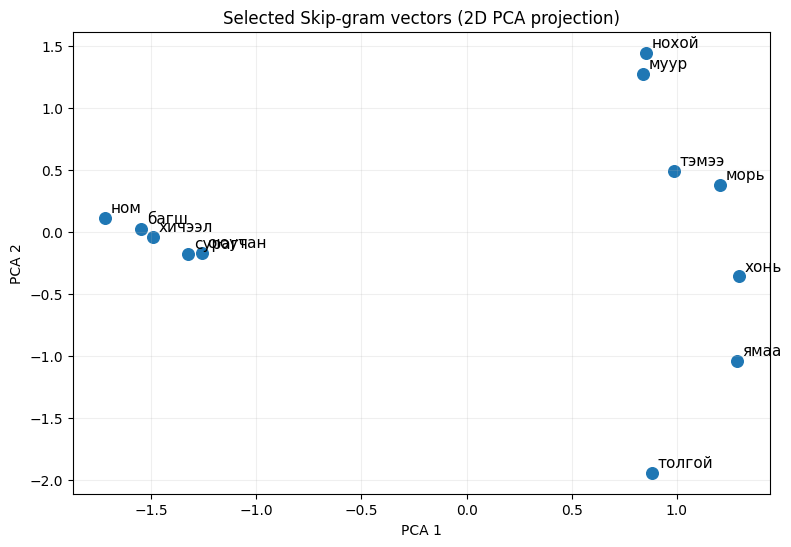

In [10]:
WORDS_TO_PLOT = [
    "муур", "нохой", "морь", "тэмээ", "хонь", "ямаа",
    "оюутан", "сурагч", "багш", "ном", "хичээл", "толгой",
]
words = [word for word in WORDS_TO_PLOT if word in skipgram_model.wv]
matrix = np.vstack([skipgram_model.wv[word] for word in words])
coordinates = PCA(n_components=2, random_state=RANDOM_SEED).fit_transform(matrix)

plt.figure(figsize=(9, 6))
plt.scatter(coordinates[:, 0], coordinates[:, 1], s=70)
for word, (x, y) in zip(words, coordinates):
    plt.annotate(word, (x, y), xytext=(4, 4), textcoords="offset points", fontsize=11)
plt.title("Selected Skip-gram vectors (2D PCA projection)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.grid(alpha=0.2)
plt.show()


PCA is a lossy two-dimensional projection. Distance on this graph is illustrative; use cosine similarity in the original embedding space for numerical comparisons.


## 8. Optional experiment: context-window size


In [11]:
window_results = []
for window in [1, 2, 5]:
    model = Word2Vec(
        sentences=sentences,
        vector_size=50,
        window=window,
        min_count=1,
        workers=1,
        seed=RANDOM_SEED,
        epochs=100,
        sg=1,
    )
    window_results.append({
        "window": window,
        "sim(муур, нохой)": model.wv.similarity("муур", "нохой"),
        "sim(хонь, ямаа)": model.wv.similarity("хонь", "ямаа"),
        "sim(оюутан, сурагч)": model.wv.similarity("оюутан", "сурагч"),
    })

display(pd.DataFrame(window_results).round(3))


,window,"sim(муур, нохой)","sim(хонь, ямаа)","sim(оюутан, сурагч)"
0,1,0.985,0.810,0.996
1,2,0.981,0.855,0.998
2,5,0.987,0.808,0.997
